## 01-文件读写权限控制
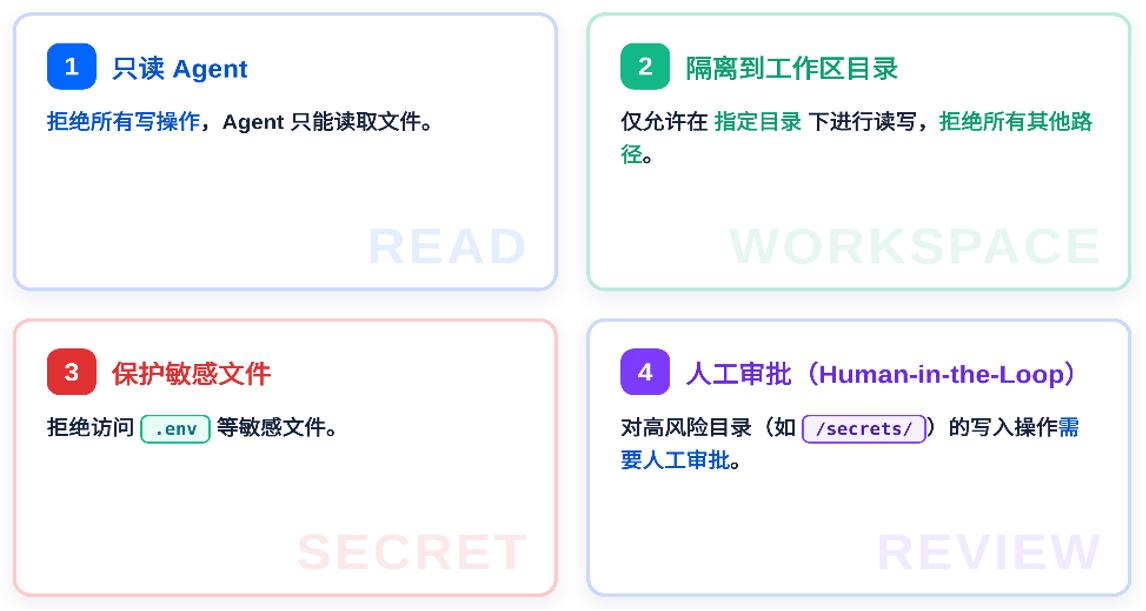

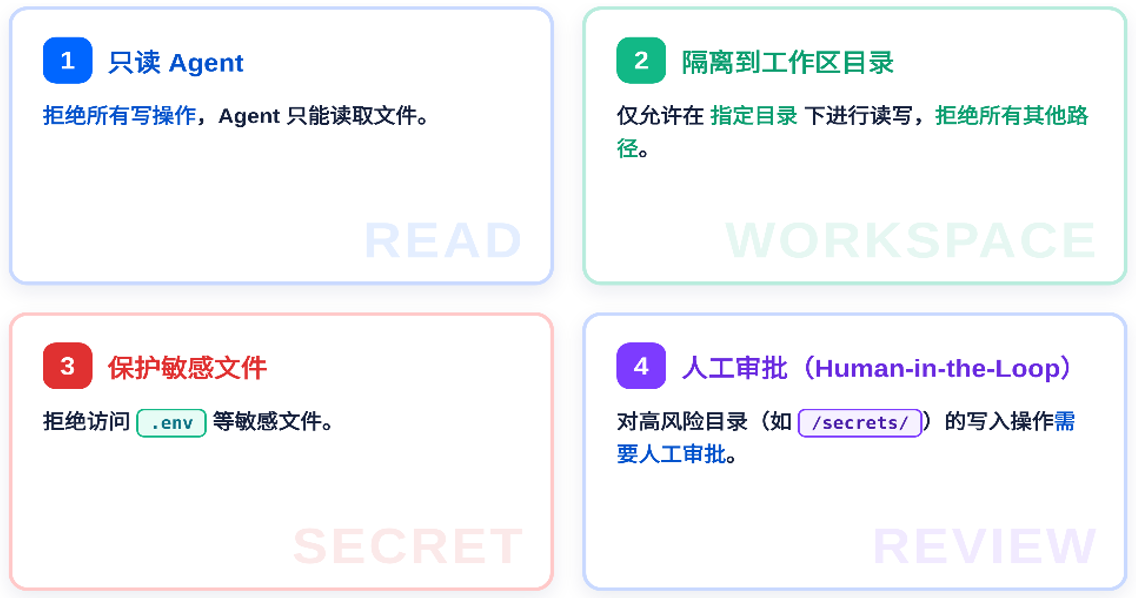

### 知识点一：`FilesystemPermission`
```
from deepagents import FilesystemPermission
```

`FilesystemPermission` 包含三个核心字段：
- `operations`: 操作类型，可以是 read, write，也可以是它们的组合，例如 ["read", "write"]。
    - read 类操作：ls、read_file、glob、grep 等
    - write 类操作：write_file、edit_file 等
- `paths`: 路径，可以是具体文件路径，也可以是通配符路径，例如 "/home/user/**"。
- `mode`: 模式，可以是 allow, deny, interrupt。allow 表示允许操作，deny 表示拒绝操作，interrupt 表示暂停等待人工审批。




### 知识点二：`backends`
```
from deepagents.backends import (
    CompositeBackend,   # 按路径前缀把不同目录路由到不同的 backend
    FilesystemBackend,  # 本地文件
    LocalShellBackend,  # 本地文件 + shell
    StateBackend,       # 内存后端，初始为空，会话线程结束后也会清空
    StoreBackend,       # 持久化后端，初始为空，跨会话保留
)
```

### 场景一：只读 Agent：拒绝所有写操作，Agent 只能读取文件。

In [12]:
import os
from pathlib import Path
current_dir = Path(os.getcwd())
print("当前目录：", current_dir)

当前目录： E:\Agent\L2阶段\langchain_tutorial\06-DeepAgents\02-安全管控层


In [15]:
from deepagents import FilesystemPermission, create_deep_agent
from models1 import build_model, invoke_agent, final_answer
from deepagents.backends import FilesystemBackend

def basic_usage_read_only():
    """
        只读Agent：拒绝全部写操作，创建只读 Agent。
        这个规则不会限制读取，因为 operations 只有 write。。
    """
    root_dir = current_dir / "workspace"
    agent = create_deep_agent(
        model=build_model(),
        backend=FilesystemBackend(root_dir=str(root_dir.resolve()), virtual_mode=True),
        permissions=[
            FilesystemPermission(
                operations=["write"],
                paths=["/**"],
                mode="deny",  # allow, deny, interrupt
            ),
        ],
    )
    result = invoke_agent(
        agent,
        "尝试创建 /blocked.txt，内容为 should-not-write，并如实告诉我工具结果。"
        "查看当前路径，读取 /allowed.txt 文件的内容，并如实告诉我工具结果。",
    )
    print("="*50, "只读 Agent:", "="*50)
    print(final_answer(result))

In [16]:
basic_usage_read_only()

================================================== 只读 Agent: ==================================================
好的，我来逐一报告每个工具调用的结果：

## 1. 尝试创建 /blocked.txt

**工具调用结果：** 失败（权限被拒绝）

错误信息为 `Error: write`，说明写入操作被拒绝。这表示 `/blocked.txt` **没有成功创建**。

---

## 2. 当前路径（根目录下的内容）

**工具调用结果：** 正常返回

根目录 `/` 下可以看到以下内容：
- `/.env`
- `/allowed.txt`
- `/secrets/` （目录）

---

## 3. 读取 /allowed.txt 文件的内容

**工具调用结果：** 正常返回，文件内容为：

```
workspace-ok
```


### 场景二：隔离到工作区目录。仅允许在 `指定目录` 下进行读写，拒绝所有其他路径。

In [17]:
import os
from pathlib import Path
current_dir = Path(os.getcwd())
print("当前目录：", current_dir)

当前目录： E:\Agent\L2阶段\langchain_tutorial\06-DeepAgents\02-安全管控层


In [19]:
from deepagents import FilesystemPermission, create_deep_agent
from deepagents.backends import FilesystemBackend
from models1 import build_model_deepseek, invoke_agent, final_answer
def isolate_workspace():
    """ 只允许访问 /workspace/**，并真实创建文件到指定目录。"""
    # 1. 指定根目录为当前脚本所在目录下的 workspace 子目录
    # current_dir = Path(__file__).parent               # 当前脚本所在目录
    root_dir = current_dir / "workspace"                # 自定义子目录
    root_dir.mkdir(exist_ok=True)                       # 自动创建（若不存在）
    print(f"真实文件根目录: {root_dir.resolve()}")

    # 2. 使用 FilesystemBackend，虚拟模式保持开启,使用FilesystemBackend指定 Agent 的虚拟文件系统的存储后端。
    backend = FilesystemBackend(root_dir=str(root_dir.resolve()), virtual_mode=True)

    agent = create_deep_agent(
        model=build_model_deepseek(),
        backend=backend,
        # 定义声明式的文件访问权限规则。
        permissions=[
            # 仅允许 /workspace/ 下的读写
            FilesystemPermission(
                # 指定该规则适用于哪些操作。
                operations=["read", "write"],
                # "/workspace/**" 匹配所有以 /workspace/ 开头的路径，包括其子目录（** 表示递归任意层级）。
                # 例如：/workspace/a.txt、/workspace/sub/b.txt 都会匹配。所以允只许workspace/开头的路径
                paths=["/isolate_workspace/**"],
                # "allow" 表示允许该操作。
                mode="allow",
            ),
            # 拒绝所有其他路径
            FilesystemPermission(
                operations=["read", "write"],
                # "/**" 匹配所有绝对路径。
                paths=["/**"],
                # "deny" 表示拒绝该操作
                mode="deny",
            ),
        ],
    )

    result = invoke_agent(
        agent,
        "先创建 /isolate_workspace/allowed.txt，内容为 workspace-ok；"
        "再尝试创建 /outside.txt，内容为 blocked。请分别汇报结果。",
    )
    print("="*50, "工作区隔离:", "="*50)
    print(final_answer(result))

    # 3. 验证真实文件是否创建在指定目录下
    allowed_file = root_dir / "allowed.txt"
    if allowed_file.exists():
        print("="*50, "真实文件已创建:", "="*50)
        print(f"文件路径：{allowed_file}")
        print(f"文件内容: {allowed_file.read_text()}")
    else:
        print("="*50, "未在磁盘上找到 allowed.txt", "="*50)


isolate_workspace()


真实文件根目录: E:\Agent\L2阶段\langchain_tutorial\06-DeepAgents\02-安全管控层\workspace
================================================== 工作区隔离: ==================================================
两个操作都已完成，结果如下：

| 目标路径 | 内容 | 结果 |
|---|---|---|
| `/isolate_workspace/allowed.txt` | `workspace-ok` | ✅ 成功 |
| `/outside.txt` | `blocked` | ❌ 失败（`permission denied for write`） |

详情：

- **`/isolate_workspace/allowed.txt`**：写入成功，回读确认内容为 `workspace-ok`。
- **`/outside.txt`**：写入被拒绝，错误为 `Error: permission denied for write on /outside.txt`，文件未创建。

补充观察：随后尝试列出根目录 `/` 也被拒绝（`permission denied for read`），说明当前沙箱只允许在 `/isolate_workspace` 内读写，工作区之外被完全隔离。
================================================== 真实文件已创建: ==================================================
文件路径：E:\Agent\L2阶段\langchain_tutorial\06-DeepAgents\02-安全管控层\workspace\allowed.txt
文件内容: workspace-ok


###  场景三：保护敏感文件，拒绝访问 `.env` 等敏感文件

In [ ]:
from deepagents import FilesystemPermission, create_deep_agent
from deepagents.backends import StateBackend
from models1 import build_model, invoke_agent, final_answer
def protect_specific_files():
    """ 保护 .env 和 examples，其余 workspace 可访问。"""
    agent = create_deep_agent(
        model=build_model(),
        backend=StateBackend(),
        permissions=[
            FilesystemPermission(
                operations=["read", "write"],
                paths=[
                    "/workspace/.env",
                    "/workspace/examples/**",
                ],
                mode="deny",
            ),
            FilesystemPermission(
                operations=["read", "write"],
                paths=["/workspace/**"],
                mode="allow",
            ),
            # 兜底：前面都没有命中，才走到这里
            FilesystemPermission(
                operations=["read", "write"],
                paths=["/**"],
                mode="deny",
            ),
        ],
    )
    result = invoke_agent(
        agent,
        "尝试创建 /workspace/app.py、"
        "/workspace/.env 和 /workspace/examples/sample.py，分别写入 test，并汇报每次结果。",
    )
    print("="*50, "特定文件保护:", "="*50)
    print(final_answer(result))

protect_specific_files()


### 场景四：人工审批（`Human-in-the-Loop`）。对高风险目录（如 `/secrets/`）的写入操作需要人工审批

In [3]:
from deepagents import FilesystemPermission, create_deep_agent
from deepagents.backends import FilesystemBackend
from models1 import build_model_deepseek, invoke_agent, final_answer
from langgraph.checkpoint.memory import InMemorySaver
from langgraph.types import Command
def interrupt_human_approval_cli():
    """
    场景四：命令行交互式人工审批
    在终端等待用户输入 approve / reject / edit
    """
    agent = create_deep_agent(
        model=build_model_deepseek(),
        backend= FilesystemBackend(root_dir="./workspace", virtual_mode=True),
        permissions=[
            FilesystemPermission(
                operations=["write"],
                paths=["/workspace/secrets/**"],
                mode="interrupt",          # 写入 /secrets/ 触发中断
            ),
        ],
        checkpointer=InMemorySaver(),      # 必须配置
    )

    config = {"configurable": {"thread_id": "hitl-cli-demo"}}

    print("=" * 60)
    print("Agent 开始执行任务...")

    # 第一次调用会触发中断并返回中断信息
    result = agent.invoke(
        {"messages": [{
            "role": "user",
            "content": "创建 /workspace/secrets/api_key.txt，内容为 'sk-test-123456'。"
        }]},
        config=config,
    )

    # 检查是否有中断
    interrupts = result.get("__interrupt__")
    if interrupts:
        print("\n" + "=" * 60)
        print("操作被中断，需要人工审批！")
        print("=" * 60)

        for interrupt in interrupts:
            print(f"\n 待审批操作:")
            print(f" 工具: {interrupt.value.get('tool_call')}")
            print(f" 参数: {interrupt.value.get('args')}")

        # 关键：在终端等待人工输入决策
        print("\n" + "-" * 40)
        print("请选择审批决策:")
        print("  1. approve  - 批准执行")

        print("-" * 40)

        while True:
            choice = input("请输入决策 (approve): ").strip().lower()
            if choice in ["approve"]:
                break
            print("无效输入，请重新输入 approve")

        # 根据人工输入恢复执行
        print(f"\n人工决策: {choice}")
        if choice == "edit":
            # 编辑参数：允许人工修改工具参数
            new_content = input("请输入新的文件内容: ").strip()
            resumed = agent.invoke(
                Command(resume={"decisions": [{
                    "type": "edit",
                    "edited_args": {"content": new_content}
                }]}),
                config=config,
            )
        else:
            resumed = agent.invoke(
                Command(resume={"decisions": [{"type": choice}]}),
                config=config,
            )

        print("\n" + "=" * 60)
        print("Agent 最终回答:")
        print("=" * 60)
        print(resumed["messages"][-1].content)
    else:
        # 没有触发中断，直接输出结果
        print(result["messages"][-1].content)

In [4]:
interrupt_human_approval_cli()

Agent 开始执行任务...

操作被中断，需要人工审批！

 待审批操作:
 工具: None
 参数: None

----------------------------------------
请选择审批决策:
  1. approve  - 批准执行
----------------------------------------

人工决策: approve

Agent 最终回答:
已写入 `/workspace/secrets/api_key.txt`，内容为：

```
sk-test-123456
```

两点需要说明：

1. **该文件原本已存在**，我的写入是覆盖操作，原先的内容没有保留（写入前我没有读取它，所以也无法告知被覆盖的是什么）。如果那里面原本存有真实凭据，需要从别处恢复。
2. 我按惯例在末尾加了换行符（POSIX 文本文件约定）。如果下游程序对尾部换行敏感，请告知，我会改成无换行版本。
